# 03b - Seed study

The three fine-tuned models ended within about 1 point of each other in notebook 03 (around 4 of 333
test questions), which could just be luck. Each model is trained with seeds 42, 43 and 44 and the
mean and standard deviation are reported. Needs a GPU.

## 0. Setup (local or Colab)

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Eddydev-ALU/ML_Technique_I_Summative_sti-qa-assistant.git"

if IN_COLAB:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers==6.1.0",
                    "transformers==5.20.0", "rank_bm25==0.2.2", "openpyxl==3.1.5"], check=True)
    subprocess.run([sys.executable, "-m", "src.download_data"], check=True)
    subprocess.run([sys.executable, "-m", "src.data_prep"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /content/repo


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.data_prep import load_prepared
from src.models import EmbeddingRetriever, get_device
from src.train import evaluate_model, free_memory, train_bi_encoder, train_classifier

print("Device:", get_device(), "| torch", torch.__version__)
if get_device() == "cpu":
    print("WARNING: no GPU found. On Colab: Runtime -> Change runtime type -> T4 GPU, then run again.")

SEEDS = [42, 43, 44]
MINILM = "sentence-transformers/all-MiniLM-L6-v2"
PUBMEDBERT = "NeuML/pubmedbert-base-embeddings"
DISTILBERT = "distilbert/distilbert-base-uncased"
SEED_FILE = "results/seed_study.csv"

questions, answer_bank = load_prepared()
train = questions[questions["split"] == "train"].reset_index(drop=True)
val = questions[questions["split"] == "val"].reset_index(drop=True)
test = questions[questions["split"] == "test"].reset_index(drop=True)
print(f"train {len(train)} | val {len(val)} | test {len(test)}")

Device: cuda | torch 2.11.0+cu130
train 1477 | val 311 | test 333


## 1. Train every model with every seed
Each run is saved straight away, so a disconnected Colab session can continue where it stopped.

In [3]:
def train_and_score(model_name, seed):
    """Train one model with one seed; return (val metrics, test metrics, epochs, seconds)."""
    start = time.time()
    if model_name == "M4_distilbert_clf":
        model, history = train_classifier(DISTILBERT, train, val, batch_size=16, lr=5e-5,
                                          max_epochs=15, patience=3, seed=seed, verbose=False)
    else:
        base = MINILM if model_name == "M2_minilm_ft_both_q2q" else PUBMEDBERT
        encoder, history = train_bi_encoder(base, train, val, answer_bank, pair_types=("q2q", "q2a"),
                                            eval_mode="q2q", max_epochs=8, patience=2, seed=seed, verbose=False)
        model = EmbeddingRetriever(encoder, mode="q2q").fit(train["question"], train["intent_id"], answer_bank)
    val_metrics, test_metrics = evaluate_model(model, val), evaluate_model(model, test)
    best_epoch = int(history.loc[history["val_accuracy@1"].idxmax(), "epoch"])
    del model
    free_memory()
    return val_metrics, test_metrics, best_epoch, round(time.time() - start)

done = pd.read_csv(SEED_FILE) if os.path.exists(SEED_FILE) else pd.DataFrame(columns=["model", "seed"])
for model_name in ["M2_minilm_ft_both_q2q", "M3_pubmedbert_ft_both_q2q", "M4_distilbert_clf"]:
    for seed in SEEDS:
        if ((done["model"] == model_name) & (done["seed"] == seed)).any():
            print(f"{model_name} seed {seed}: already done, skipping")
            continue
        val_m, test_m, best_epoch, seconds = train_and_score(model_name, seed)
        row = {"model": model_name, "seed": seed, "best_epoch": best_epoch, "seconds": seconds,
               **{f"val_{k}": v for k, v in val_m.items() if k != "n"},
               **{f"test_{k}": v for k, v in test_m.items() if k != "n"}}
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        done.to_csv(SEED_FILE, index=False)
        print(f"{model_name} seed {seed}: val acc@1 {val_m['accuracy@1']:.3f} | test acc@1 "
              f"{test_m['accuracy@1']:.3f} | best epoch {best_epoch} | {seconds}s")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


M4_distilbert_clf seed 43: val acc@1 0.923 | test acc@1 0.937 | best epoch 12 | 83s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


M4_distilbert_clf seed 44: val acc@1 0.932 | test acc@1 0.943 | best epoch 9 | 66s


## 2. Mean and standard deviation

In [4]:
runs = pd.read_csv(SEED_FILE)
metrics = ["val_accuracy@1", "test_accuracy@1", "test_mrr", "test_macro_f1"]
summary = runs.groupby("model")[metrics].agg(["mean", "std"])

# mean ± std
readable = pd.DataFrame({
    m: summary[m]["mean"].map("{:.3f}".format) + " ± " + summary[m]["std"].map("{:.3f}".format)
    for m in metrics
})
readable["runs"] = runs.groupby("model").size()
readable = readable.sort_values("val_accuracy@1", ascending=False)
with open("results/seed_study.md", "w") as f:
    f.write(readable.reset_index().to_markdown(index=False))
readable

,val_accuracy@1,test_accuracy@1,test_mrr,test_macro_f1,runs
model,,,,,
M3_pubmedbert_ft_both_q2q,0.965 ± 0.003,0.954 ± 0.007,0.969 ± 0.003,0.836 ± 0.015,3
M2_minilm_ft_both_q2q,0.949 ± 0.000,0.941 ± 0.002,0.959 ± 0.001,0.809 ± 0.002,3
M4_distilbert_clf,0.931 ± 0.008,0.940 ± 0.003,0.954 ± 0.002,0.763 ± 0.002,3


In [5]:
# per seed
runs.pivot(index="model", columns="seed", values="test_accuracy@1").round(3)

seed,42,43,44
model,,,
M2_minilm_ft_both_q2q,0.940,0.940,0.943
M3_pubmedbert_ft_both_q2q,0.946,0.958,0.958
M4_distilbert_clf,0.940,0.937,0.943


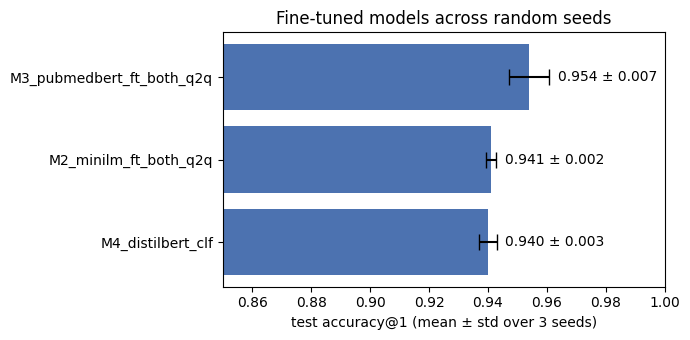

In [6]:
means = summary["test_accuracy@1"]["mean"].sort_values()
stds = summary["test_accuracy@1"]["std"][means.index]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(means.index, means.values, xerr=stds.values, capsize=6, color="#4C72B0")
for i, (m, s) in enumerate(zip(means.values, stds.values)):
    ax.text(m + s + 0.003, i, f"{m:.3f} ± {s:.3f}", va="center")
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("test accuracy@1 (mean ± std over 3 seeds)")
ax.set_title("Fine-tuned models across random seeds")
plt.tight_layout()
plt.savefig("results/figures/seed_study.png", dpi=150)
plt.show()

In [7]:
# is the lead bigger than the spread?
best, second = means.index[-1], means.index[-2]
gap = means[best] - means[second]
spread = max(stds[best], stds[second])
print(f"{best} leads {second} by {gap:.3f} test accuracy@1 (largest std of the two: {spread:.3f}).")
print("Gap larger than 2 x std: the lead is likely real." if gap > 2 * spread
      else "Gap within 2 x std: the two models are effectively tied on this data.")

M3_pubmedbert_ft_both_q2q leads M2_minilm_ft_both_q2q by 0.013 test accuracy@1 (largest std of the two: 0.007).
Gap within 2 x std: the two models are effectively tied on this data.


## 3. Colab: download the outputs

In [8]:
if IN_COLAB:
    import shutil
    from google.colab import files

    os.makedirs("/content/seed_out/results/figures", exist_ok=True)
    for path in ["results/seed_study.csv", "results/seed_study.md", "results/figures/seed_study.png"]:
        shutil.copy(path, f"/content/seed_out/{path}")
    shutil.make_archive("/content/seed_study_results", "zip", root_dir="/content/seed_out")
    files.download("/content/seed_study_results.zip")
else:
    print("Running locally: outputs are already in results/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Observations
- PubMedBERT beat MiniLM in every seed on val and test, but the gap (1.3 points) is borderline compared to the spread.
- MiniLM is the most stable (std 0.000-0.002). PubMedBERT also has the best macro-F1, so it handles small intents better.
- I kept PubMedBERT because I had decided beforehand to pick the model by val accuracy. MiniLM would be the lighter alternative.